<a href="https://colab.research.google.com/github/p-anshu8896/Awesome-CV/blob/master/DA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
!pip install pandas
!pip install numpy
!pip install matplotlib

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
df = pd.read_csv(r'/content/retail_sales_messy.csv')
print(df)

    order_id  order_date region   product sales_channel  quantity  unit_price  \
0    ORD0001  2026-01-17   East     Phone        Online       1.0     28000.0   
1    ORD0002  2026-05-20   West     Phone        Online       5.0     28000.0   
2    ORD0003  28/04/2026  South     Phone        Online       3.0     28000.0   
3    ORD0004  2026-03-20  North    Tablet         Store       2.0     22000.0   
4    ORD0005  2026-03-19  North   Monitor        Online       1.0     15000.0   
..       ...         ...    ...       ...           ...       ...         ...   
498  ORD0499  16/06/2026   West  Keyboard        Online       6.0      1800.0   
499  ORD0500  2026-03-18   West  Keyboard        Online       4.0      1800.0   
500  ORD0006  2026-06-04   East     Phone       Partner       7.0     28000.0   
501  ORD0026  2026-04-26  South  Keyboard        Online       2.0      1800.0   
502  ORD0101  2026-05-30   East    Laptop         Store       4.0     65000.0   

             sales         

In [11]:
df.columns

Index(['order_id', 'order_date', 'region', 'product', 'sales_channel',
       'quantity', 'unit_price', 'sales', 'cost', 'profit'],
      dtype='object')

In [12]:
df.head(10)

,order_id,order_date,region,product,sales_channel,quantity,unit_price,sales,cost,profit
0,ORD0001,2026-01-17,East,Phone,Online,1.0,28000.0,30303.158830,20597.876500,9705.282330
1,ORD0002,2026-05-20,West,Phone,Online,5.0,28000.0,138198.686936,101688.320258,36510.366678
2,ORD0003,28/04/2026,South,Phone,Online,3.0,28000.0,93131.979257,70679.989705,22451.989552
3,ORD0004,2026-03-20,North,Tablet,Store,2.0,22000.0,45592.390867,33175.241263,12417.149604
4,ORD0005,2026-03-19,North,Monitor,Online,1.0,15000.0,13617.235915,9012.150471,4605.085445
5,ORD0006,2026-06-04,East,Phone,Partner,7.0,28000.0,214114.774166,145899.367444,68215.406723
6,ORD0007,2026-01-16,West,Phone,Store,6.0,28000.0,167567.172494,127023.685507,40543.486987
7,ORD0008,2026-05-06,North,Keyboard,Store,6.0,1800.0,9871.128205,5713.864457,4157.263748
8,ORD0009,2026-02-06,North,Laptop,Online,1.0,65000.0,59581.966088,46654.709638,12927.256450
9,ORD0010,2026-01-17,East,Tablet,Partner,3.0,22000.0,68970.537532,49103.895777,19866.641755


In [13]:
df.shape

(503, 10)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       503 non-null    object 
 1   order_date     503 non-null    object 
 2   region         491 non-null    object 
 3   product        503 non-null    object 
 4   sales_channel  503 non-null    object 
 5   quantity       493 non-null    float64
 6   unit_price     496 non-null    float64
 7   sales          503 non-null    float64
 8   cost           503 non-null    float64
 9   profit         503 non-null    float64
dtypes: float64(5), object(5)
memory usage: 39.4+ KB


In [15]:
df.describe()

,quantity,unit_price,sales,cost,profit
count,493.000000,496.000000,503.000000,503.000000,503.000000
mean,4.008114,27027.822581,105760.623312,78101.499411,27659.123902
std,2.003030,20940.823600,104255.238094,81356.490273,23745.609212
min,1.000000,1800.000000,1586.098370,856.563486,683.095172
25%,2.000000,15000.000000,26365.042443,18471.915392,7696.132747
50%,4.000000,22000.000000,79103.058282,55217.125424,22920.543768
75%,6.000000,28000.000000,143202.703084,104221.247005,39161.553356
max,7.000000,65000.000000,468863.195575,371175.476740,116900.923075


In [16]:
df.isnull().sum()

,0
order_id,0
order_date,0
region,12
product,0
sales_channel,0
quantity,10
unit_price,7
sales,0
cost,0
profit,0


In [17]:
df.duplicated().sum()

np.int64(3)

In [18]:
df[df.duplicated()].count()

,0
order_id,3
order_date,3
region,3
product,3
sales_channel,3
quantity,3
unit_price,3
sales,3
cost,3
profit,3


In [19]:
isnull = df.isnull().sum()
print(isnull)

order_id          0
order_date        0
region           12
product           0
sales_channel     0
quantity         10
unit_price        7
sales             0
cost              0
profit            0
dtype: int64


In [20]:
missingPercentage = (df.isnull().sum()/len(df))*100
print(missingPercentage)

order_id         0.000000
order_date       0.000000
region           2.385686
product          0.000000
sales_channel    0.000000
quantity         1.988072
unit_price       1.391650
sales            0.000000
cost             0.000000
profit           0.000000
dtype: float64


In [21]:
from IPython.core import error
df['order_date'] = pd.to_datetime(df['order_date'],errors = 'coerce',dayfirst=True)

/tmp/ipykernel_2086/3633538779.py:2: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df['order_date'] = pd.to_datetime(df['order_date'],errors = 'coerce',dayfirst=True)


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       503 non-null    object        
 1   order_date     475 non-null    datetime64[ns]
 2   region         491 non-null    object        
 3   product        503 non-null    object        
 4   sales_channel  503 non-null    object        
 5   quantity       493 non-null    float64       
 6   unit_price     496 non-null    float64       
 7   sales          503 non-null    float64       
 8   cost           503 non-null    float64       
 9   profit         503 non-null    float64       
dtypes: datetime64[ns](1), float64(5), object(4)
memory usage: 39.4+ KB


In [23]:
# remaining missing values
df.isnull().sum()

,0
order_id,0
order_date,28
region,12
product,0
sales_channel,0
quantity,10
unit_price,7
sales,0
cost,0
profit,0


In [24]:
# the number of invalid dates.
df['order_date'].isnull().sum()

np.int64(28)

In [25]:
# Re-initialize and clean clean_df to restore the overwritten 'sales' column
clean_df = df.copy()
clean_df['region'] = clean_df['region'].fillna('Unknown')
clean_df['quantity'] = clean_df['quantity'].fillna(df['quantity'].mean())
clean_df['unit_price'] = clean_df['unit_price'].fillna(df['unit_price'].mean())
clean_df = clean_df.dropna(subset=['order_date']).copy()

In [26]:
clean_df['region']  = clean_df['region'].fillna('Unknown')
clean_df['region'].isnull().sum()
print(clean_df['region'])

0       East
1       West
3      North
4      North
5       East
       ...  
497    South
499     West
500     East
501    South
502     East
Name: region, Length: 475, dtype: object


In [27]:
clean_df['quantity'] = clean_df['quantity'].fillna(df['quantity'].mean())
clean_df['quantity'].isnull().sum()

np.int64(0)

In [28]:
clean_df['unit_price'] = clean_df['unit_price'].fillna(df['unit_price'].mean())
clean_df['unit_price'].isnull().sum()

np.int64(0)

In [29]:
clean_df = clean_df.dropna(subset= ['order_date']).copy()
clean_df['order_date'].isnull().sum()
clean_df.shape


(475, 10)

In [30]:
quantity_product = clean_df['quantity']*clean_df['unit_price']
print(quantity_product)

0       28000.000000
1      140000.000000
3       44000.000000
4       15000.000000
5      196000.000000
           ...      
497    112227.180527
499      7200.000000
500    196000.000000
501      3600.000000
502    260000.000000
Length: 475, dtype: float64


In [31]:
cost = clean_df['cost'].sum()
profit = quantity_product.sum()- cost
print(profit)

13933770.701446302


In [32]:
# Calculate the mean, median, and standard deviation of sales without overwriting the column
sales_stats = clean_df['sales'].agg(['mean', 'median', 'std'])
print(sales_stats)


mean      108086.878551
median     79527.352085
std       106209.531189
Name: sales, dtype: float64


In [33]:
# Group the data by region and calculate correct metrics with restored sales data
region_summary = clean_df.groupby('region').agg(
    total_sales=('sales', 'sum'),
    average_sales=('sales', 'mean'),
    total_profit=('profit', 'sum'),
    number_of_orders=('order_id', 'count')
).reset_index()

print(region_summary)

    region   total_sales  average_sales  total_profit  number_of_orders
0     East  1.153746e+07  115374.583107  3.050350e+06               100
1    North  1.314402e+07  105152.131417  3.397796e+06               125
2    South  1.358251e+07  115106.009914  3.481607e+06               118
3  Unknown  9.475787e+05   78964.888292  2.329640e+05                12
4     West  1.212970e+07  101080.872870  3.220829e+06               120


In [34]:
number_of_orders = clean_df.groupby('region')['order_id'].count().reset_index(name='number_of_orders')
print(number_of_orders)

    region  number_of_orders
0     East               100
1    North               125
2    South               118
3  Unknown                12
4     West               120


In [35]:
# Group the data by region and calculate: total profit
total_profit = clean_df.groupby('region')['profit'].sum().reset_index()
print(total_profit)

    region        profit
0     East  3.050350e+06
1    North  3.397796e+06
2    South  3.481607e+06
3  Unknown  2.329640e+05
4     West  3.220829e+06


In [36]:
# Sort the results by total sales in descending order.
sorted_summary = region_summary.sort_values(by='total_sales', ascending=False)
print(sorted_summary)

    region   total_sales  average_sales  total_profit  number_of_orders
2    South  1.358251e+07  115106.009914  3.481607e+06               118
1    North  1.314402e+07  105152.131417  3.397796e+06               125
4     West  1.212970e+07  101080.872870  3.220829e+06               120
0     East  1.153746e+07  115374.583107  3.050350e+06               100
3  Unknown  9.475787e+05   78964.888292  2.329640e+05                12


In [37]:
# Identify the region with the highest total sales.
highest_sales_region = sorted_summary.iloc[0]
print(f"The region with the highest total sales is: {highest_sales_region['region']} with a total of {highest_sales_region['total_sales']:.2f} in sales.")

The region with the highest total sales is: South with a total of 13582509.17 in sales.


In [38]:
# Sort the results by total sales in descending order.
sorted_summary = region_summary.sort_values(by='total_sales', ascending=False)
print(sorted_summary)

    region   total_sales  average_sales  total_profit  number_of_orders
2    South  1.358251e+07  115106.009914  3.481607e+06               118
1    North  1.314402e+07  105152.131417  3.397796e+06               125
4     West  1.212970e+07  101080.872870  3.220829e+06               120
0     East  1.153746e+07  115374.583107  3.050350e+06               100
3  Unknown  9.475787e+05   78964.888292  2.329640e+05                12


In [39]:
# Identify the region with the highest total sales.
print(sorted_summary.iloc[0])

region                        South
total_sales         13582509.169855
average_sales         115106.009914
total_profit         3481606.536612
number_of_orders                118
Name: 2, dtype: object


In [40]:
pip install matplotlib

In [41]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [56]:
df['order_date'] = pd.to_datetime(df['order_date'])
monthly_sales = df.groupby(df['order_date'].dt.to_period('M'))['sales'].sum()
print(monthly_sales)

order_date
2026-01    8.633609e+06
2026-02    6.158961e+06
2026-03    9.086444e+06
2026-04    9.149469e+06
2026-05    1.024980e+07
2026-06    8.062985e+06
Freq: M, Name: sales, dtype: float64


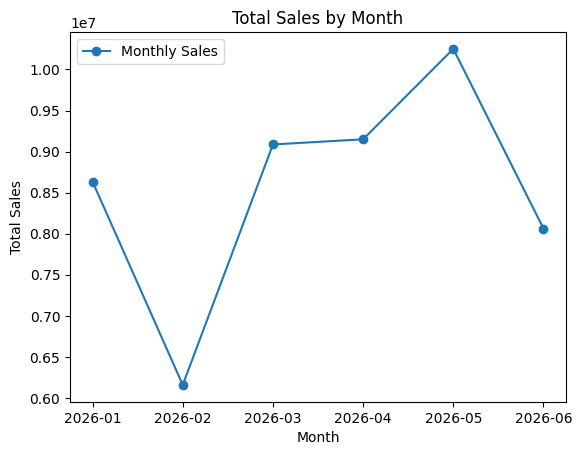

In [54]:
# Group sales by month using order_date.
# Draw a line chart.
# Include a title, axis labels, and legend.

plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker='o', label='Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.title('Total Sales by Month')
plt.legend()
plt.show()

/tmp/ipykernel_2086/4100096424.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


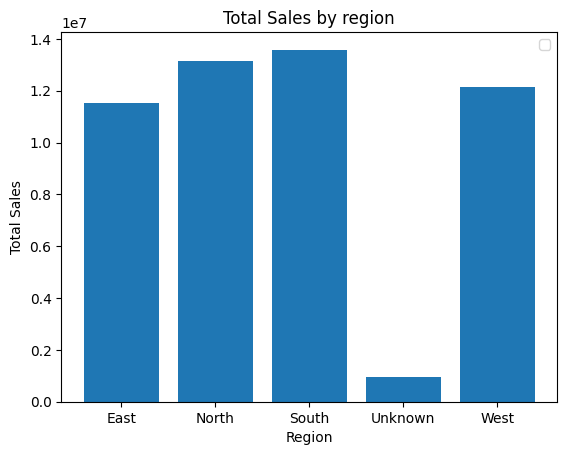

In [61]:
plt.bar(region_summary['region'],region_summary['total_sales'])
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.title('Total Sales by region')
plt.legend()
plt.show()